# imports

In [1]:
import sys
import os
import json
import numpy as np
import scipy as sp
import pandas as pd

import importlib

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils
from utils import analysis_utils

from utils import ai_slob

In [2]:
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(analysis_utils)

importlib.reload(ai_slob)

<module 'utils.ai_slob' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/organisms/mouse-2019-stringer/notebooks/analysis/../../../../utils/ai_slob.py'>

In [3]:
# specific

from sklearn.decomposition import PCA
from matplotlib import pyplot as plt

sys.path.append(os.path.join(os.getcwd(), '../../src/'))
from utils_mouse import read_utils

In [4]:
importlib.reload(read_utils)

<module 'utils_mouse.read_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/organisms/mouse-2019-stringer/notebooks/analysis/../../src/utils_mouse/read_utils.py'>

# setup

In [5]:
ll = 'll00'
data_variant = 'gcamp'

save = True

In [6]:
# specific

model_variant = 'ss'
organism = 'mouse'
manual = False
full = True

In [7]:
file_id = 2

In [8]:
# Parameters
file_id = 2


In [9]:
max_noi = 20
neurons_of_interest = []
bhl_selection = ['run']

# load

In [10]:
state_key, state_label = analysis_utils.get_plot_class(organism)
model_path = read_utils.get_model_path()

filename, traces, behavior, classes, timestamps, aux = analysis_utils.read_data(organism, file_id)
metadata = (filename, model_path, model_variant, data_variant, manual, full)

neuron_labels = analysis_utils.get_significant_neurons(filename, model_variant)[:max_noi]
for neuron in neurons_of_interest:
	if neuron not in neuron_labels and neuron in traces.columns:
		neuron_labels.append(neuron)

# traces

In [11]:
bom_params, hgm_params = analysis_utils.read_models(*metadata)

((_, bom_man, bom_rec, bom_res, bom_pres, bom_resss, bom_bss),
 (_, hgm_man, hgm_rec, hgm_res, hgm_pres, hgm_resss, hgm_bss)) = analysis_utils.read_predictions(*metadata)

bom_manifolds, bom_manifold_vars_expl = analysis_utils.postprocess_manifold(bom_man, traces, bom_params)
hgm_manifolds, hgm_manifold_vars_expl = analysis_utils.postprocess_manifold(bom_man, traces, bom_params)

In [12]:
# (pca_modes, _, _,
#  pca_vars_expl) = train_utils.get_manifolds_pca(
# 	[traces],
# 	scale=False, n_pc=hgm_man[0].values.shape[1])
# (cca_modes, _, _, _, _, _,
#  cca_vars_expl, cca_vars_expl_rs) = train_utils.get_manifolds_cca(
# 	[traces], [classes[bhl_selection]],
# 	scale=False, n_cv=hgm_man[0].values.shape[1], n_pc=classes[bhl_selection].values.shape[1])
# (plsc_modes, _, _, _, _, _,
#  plsc_vars_expl) = train_utils.get_manifolds_plsc(
# 	[traces], [classes[bhl_selection]],
# 	scale=False, n_ls=hgm_man[0].values.shape[1])

# traces by gating

In [13]:
sigmoid = lambda x: 1 / (1 + np.exp(-x))
modes = hgm_bss[0].shape[1] + 1
columns = [f'Mode {i+1}' for i in range(modes)]

In [14]:
hgm_man_zs = [(hgm_man[s].values - hgm_man[s].values.mean(axis=0)) / np.where((N_std := hgm_man[s].values.std(axis=0)) == 0.0, 1.0, N_std) for s in range(len(hgm_man))]
WMs = [hgm_params[s]['model']['WM'] for s in range(len(hgm_params))]
VBs = [hgm_params[s]['model']['VB'] for s in range(len(hgm_params))]

gating_term = [pd.DataFrame(sigmoid(hgm_man_zs[s] @ WMs[s]) @ VBs[s], columns=traces.columns) for s in range(len(hgm_man_zs))]

In [15]:
pca_pres = PCA(n_components=modes)
pca_pres.fit(hgm_pres[0].values)

,n_components,17
,copy,True
,whiten,False
,svd_solver,'auto'
,tol,0.0
,iterated_power,'auto'
,n_oversamples,10
,power_iteration_normalizer,'auto'
,random_state,None


1.0000001


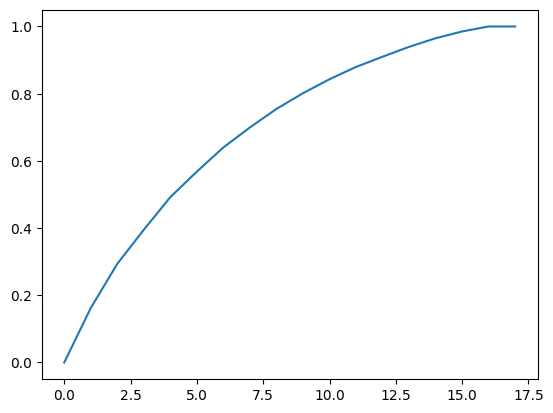

In [16]:
plt.plot([sum(pca_pres.explained_variance_ratio_[:k]) for k in range(modes+1)])
print(sum(pca_pres.explained_variance_ratio_[:modes+1]))

In [17]:
bom_pres_modes = [pd.DataFrame(pca_pres.transform(bom_pres[s].values), columns=columns) for s in range(len(bom_pres))]
hgm_pres_modes = [pd.DataFrame(pca_pres.transform(hgm_pres[s].values), columns=columns) for s in range(len(hgm_pres))]

bom_res_modes = [pd.DataFrame(pca_pres.transform(bom_res[s].values), columns=columns) for s in range(len(bom_res))]
hgm_res_modes = [pd.DataFrame(pca_pres.transform(hgm_res[s].values), columns=columns) for s in range(len(hgm_res))]

In [18]:
gating_term_modes = [pd.DataFrame(pca_pres.transform(gating_term[s].values), columns=columns) for s in range(len(gating_term))]

In [19]:
# gating_term_2 = [pd.DataFrame(hgm_man_zs[s] @ WMs[s], columns=hgm_bss[s].columns) for s in range(len(hgm_man_zs))]
# gating_term_2_man = [pd.DataFrame(PCA(n_components=gating_term_2[s].values.shape[1]).fit_transform(gating_term_2[s].values), columns=gating_term_2[s].columns) for s in range(len(gating_term_2))]
# # gating_term_2_modes = [pd.DataFrame(pca_pres.transform(gating_term_2[s].values), columns=columns) for s in range(len(gating_term_2))]
#
# plot_utils.plot_manifolds([f'{str(file_id)}: {filename} s{s}' for s in range(len(gating_term_modes))],
# 							  [gating_term_2_man[s] for s in range(len(gating_term_modes))],
# 							  [classes for s in range(len(gating_term_modes))],
# 							  None, None,
# 							  title='gating term modes', plots_per_row=len(gating_term_modes), top_space=3.5,
# 							  save_path=f'../../out/plots/manifolds/{filename}/{model_variant}_hgm_states' if save else None)

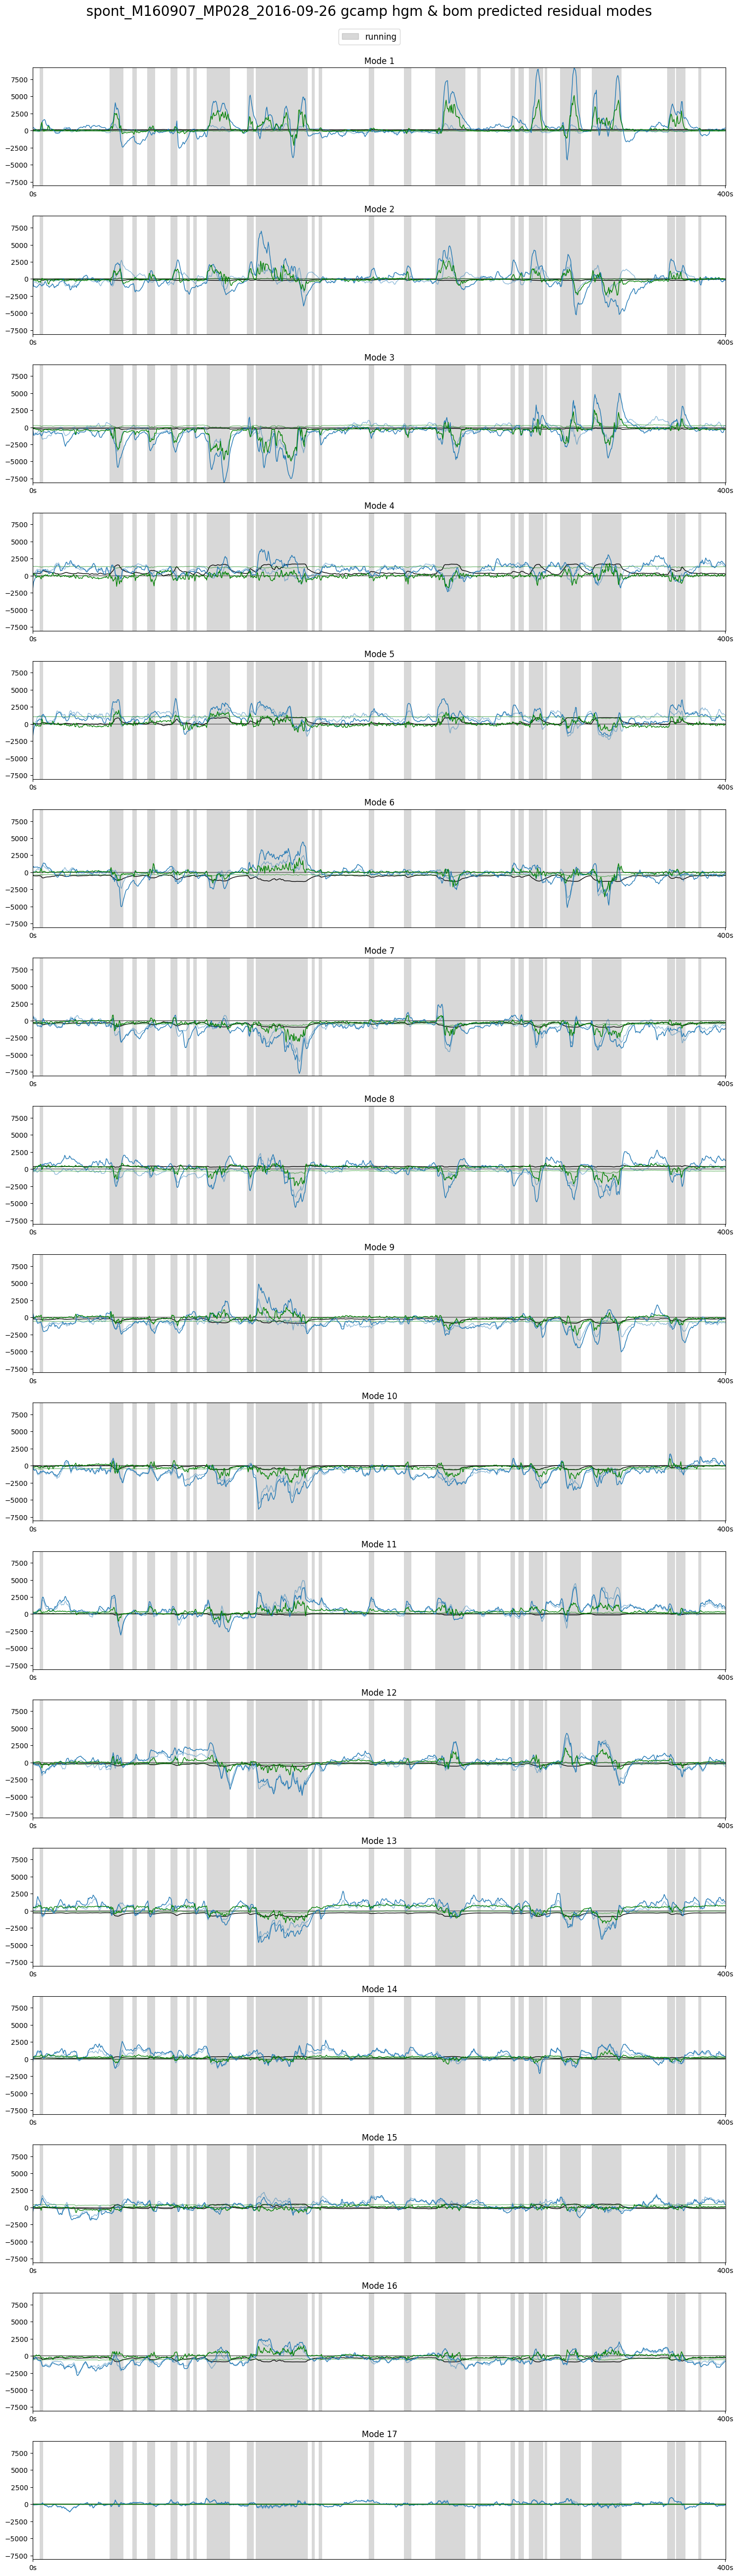

In [20]:
max_x = 1000
# max_x = traces.values.shape[0]

for s in range(len(hgm_res)):
	plot_utils.plot_traces_splits_pairs(
		[hgm_res_modes[s].loc[:max_x],
		 hgm_pres_modes[s].loc[:max_x]],
		[bom_res_modes[s].loc[:max_x],
		 bom_pres_modes[s].loc[:max_x]],
		# None,
		gating_term_modes[s].loc[:max_x],  # * hgm_pres_modes[s].loc[:max_x].max()
		classes.loc[:max_x, [state_key]],
		timestamps,
		label=state_label,
		title=f'{filename} gcamp hgm & bom predicted residual modes' + (f' s{s}' if len(hgm_res) > 1 else ''), ylimits=None, plots_per_row=1,
		save_path=f'../../out/plots/traces/{filename}/{model_variant}_model_predicted_residuals_modes' + (f'_s{s}' if len(hgm_res) > 1 else '') if save else None)

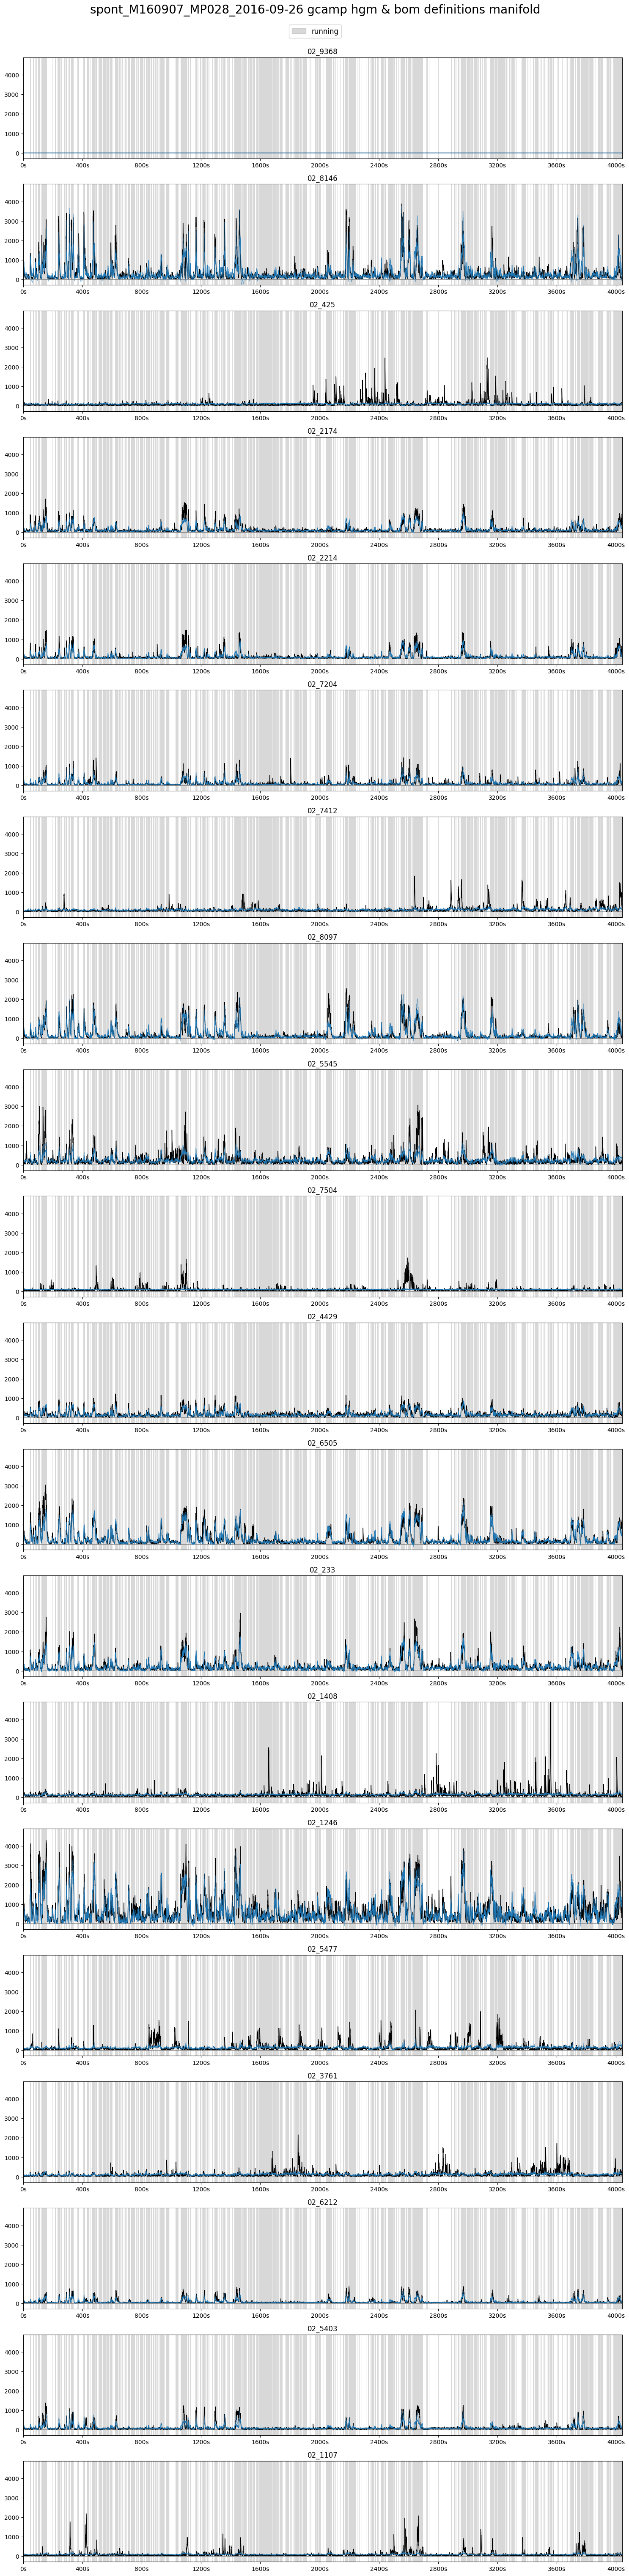

In [21]:
# max_x = 1000
max_x = traces.values.shape[0]

plot_utils.plot_traces_splits(
	[hgm_rec[i].loc[:max_x, neuron_labels] for i in range(len(hgm_rec))],
	[bom_rec[i].loc[:max_x, neuron_labels] for i in range(len(bom_rec))],
	traces.loc[:max_x, neuron_labels],
	classes.loc[:max_x, [state_key]],
	timestamps,
	label=state_label,
	title=f'{filename} gcamp hgm & bom definitions manifold', ylimits=None, plots_per_row=1,
	save_path=f'../../out/plots/traces/{filename}/{model_variant}_model_reconstructions' if save else None)

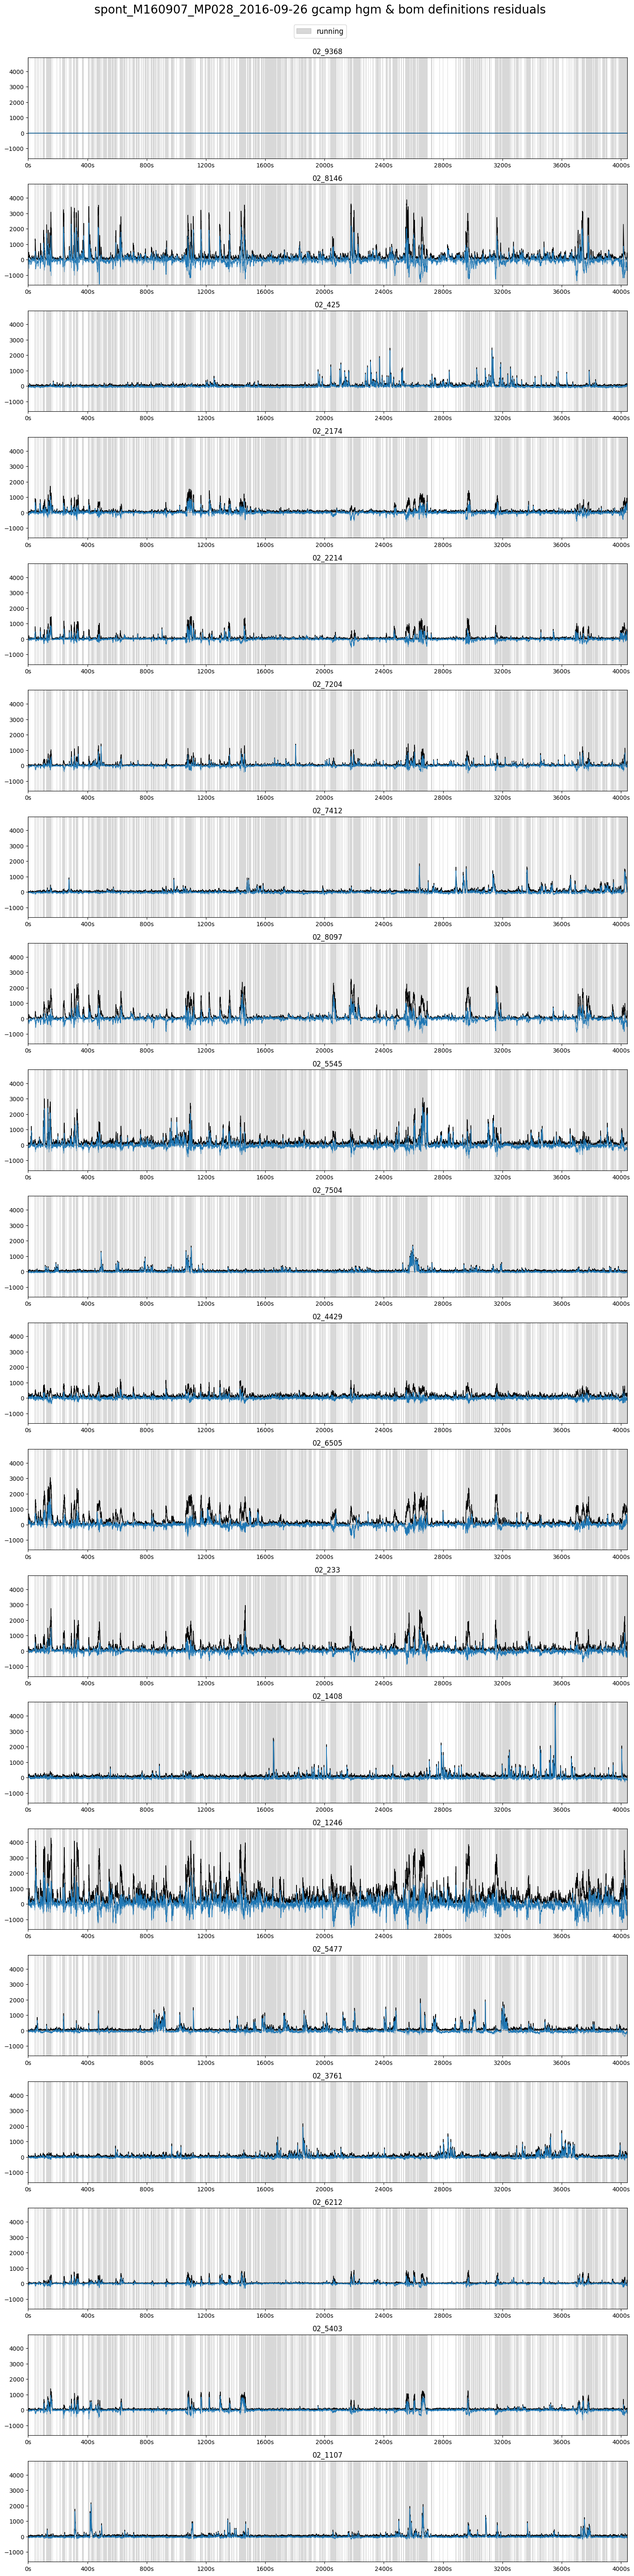

In [22]:
# max_x = 1000
max_x = traces.values.shape[0]

plot_utils.plot_traces_splits(
	[hgm_res[i].loc[:max_x, neuron_labels] for i in range(len(hgm_res))],
	[bom_res[i].loc[:max_x, neuron_labels] for i in range(len(bom_res))],
	traces.loc[:max_x, neuron_labels],
	classes.loc[:max_x, [state_key]],
	timestamps,
	label=state_label,
	title=f'{filename} gcamp hgm & bom definitions residuals', ylimits=None, plots_per_row=1,
	save_path=f'../../out/plots/traces/{filename}/{model_variant}_model_residuals' if save else None)

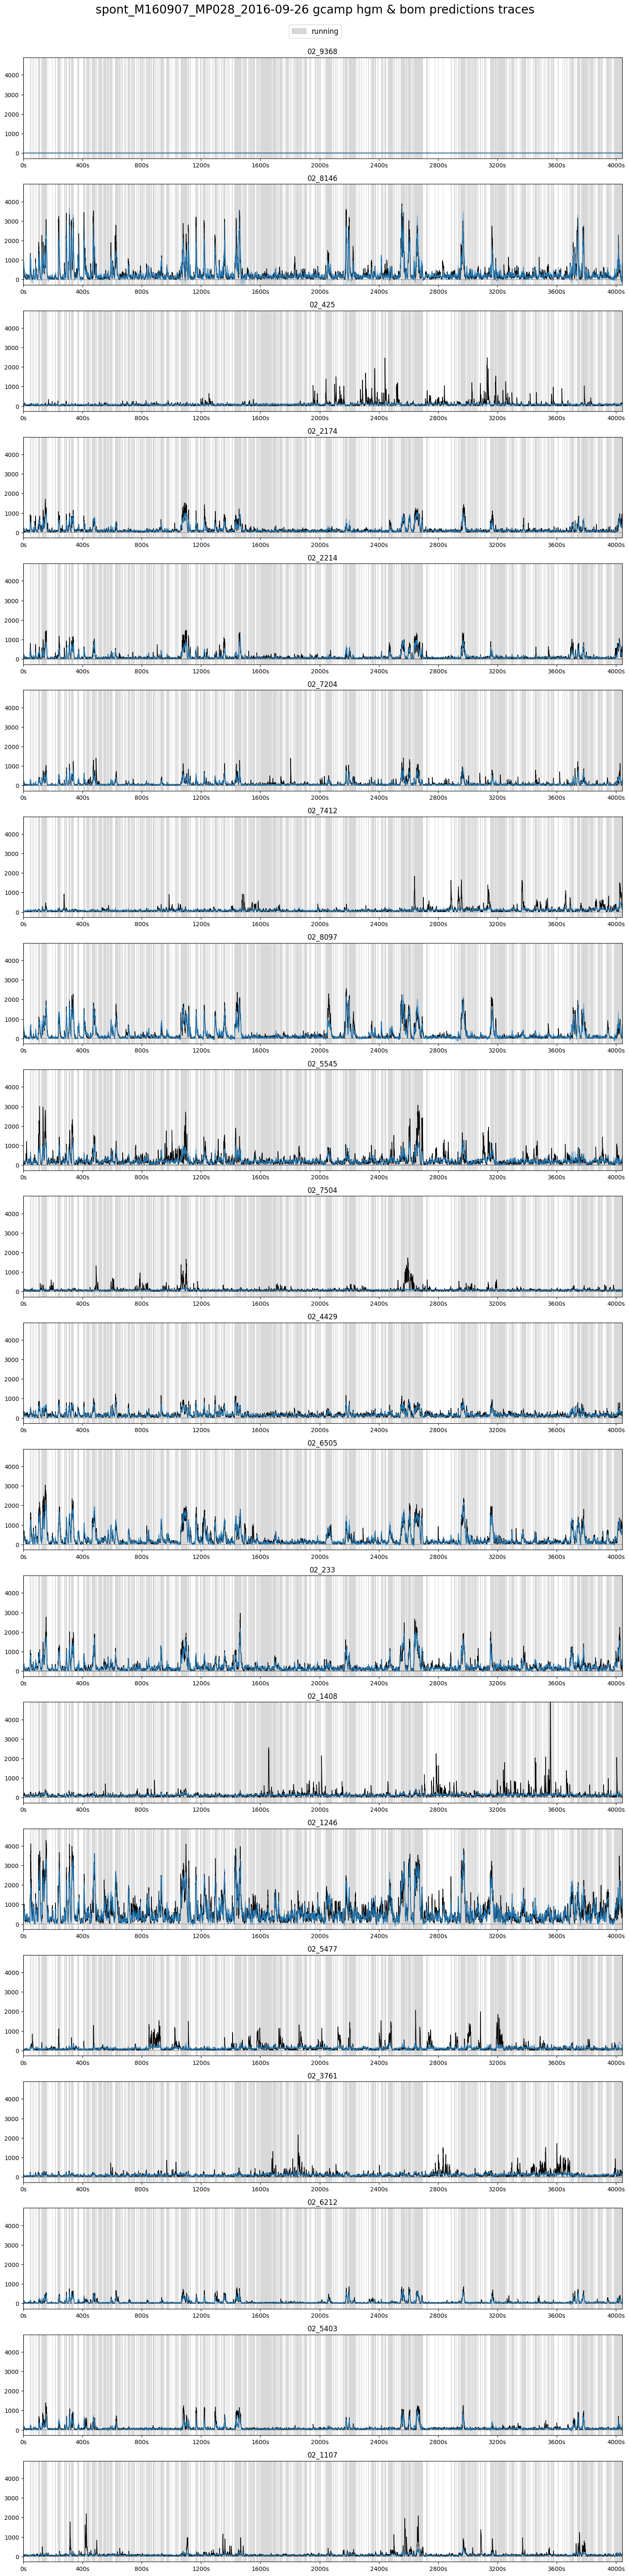

In [23]:
hgm_tra = [pd.DataFrame(hgm_rec[s].values + hgm_pres[s].values, columns=hgm_rec[s].columns) for s in range(len(hgm_rec))]
bom_tra = [pd.DataFrame(bom_rec[s].values + bom_pres[s].values, columns=bom_rec[s].columns) for s in range(len(bom_rec))]


# max_x = 1000
max_x = traces.values.shape[0]

plot_utils.plot_traces_splits(
	[hgm_tra[i].loc[:max_x, neuron_labels] for i in range(len(hgm_tra))],
	[bom_tra[i].loc[:max_x, neuron_labels] for i in range(len(bom_tra))],
	# None,
	traces.loc[:max_x, neuron_labels],
	classes.loc[:max_x, [state_key]],
	timestamps,
	label=state_label,
	title=f'{filename} gcamp hgm & bom predictions traces', ylimits=None, plots_per_row=1,
	save_path=f'../../out/plots/traces/{filename}/{model_variant}_model_predicted_traces' if save else None)